# Inference demo: detector on 5 freshly generated spectrograms

Loads `runs/detector_1cls_yolo26s_1/best.pt` (single-class YOLO26s signal detector) and runs it on **5 random synthetic scenes**.
Each scene holds **1 to 5 signals** with a random modulation and a random SNR (5 to 10 dB, set by `SNR_RANGE`). The signals are made with the *same generator* as `01_create_dataset.ipynb` (its code cells are executed here, so nothing is duplicated).

On every plot: solid boxes = ground truth with **modulation + SNR** label, dashed red boxes = detector output with confidence.

numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.0 | python 3.12.11
profile=pilot  scenes=15,000  workers=14  store_iq=True
samples/scene=33536  duration=131.0 ms  bin width=250 Hz  window=4.0 ms  out=dataset/spectrum_rf_v0.2.0_pilot


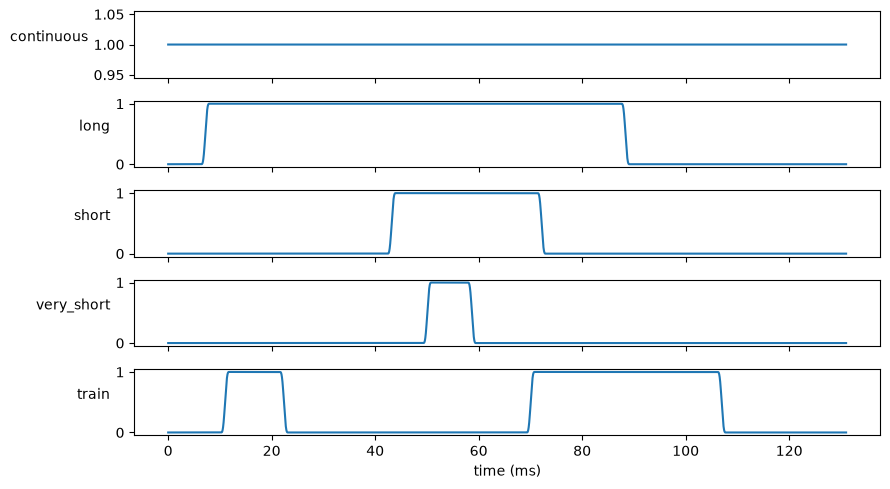

generator ready: ['CW', 'AM', 'NBFM', 'BPSK', 'QPSK', '8PSK', '16QAM', '64QAM', '2-FSK', '4-FSK', 'GMSK']


In [20]:
import json, os, sys
from pathlib import Path
import numpy as np

ROOT = Path.cwd()
nb_src = json.loads((ROOT / "01_create_dataset.ipynb").read_text())
# generator cells: imports, config, classes, signals, bursts, receiver, scene composer, sessions (stop before the demo at the end of the last one)
for idx in (1, 3, 5, 7, 9, 11, 13, 15):
    src = "".join(nb_src["cells"][idx]["source"])
    src = src.split("_demo = make_specs")[0]
    exec(compile(src, f"01_create_dataset.ipynb[cell {idx}]", "exec"), globals())
print("generator ready:", [c[1] for c in CLASS_TABLE])

In [21]:
sys.path.insert(0, str(ROOT))
from train_detector import Detector
from spectrum_common import box_iou_matrix

WEIGHTS = Path(os.environ.get("DETECTOR_WEIGHTS", ROOT / "runs/detector_1cls_yolo26s_7/best.pt"))
det = Detector(WEIGHTS, conf=0.25)
print("imgsz", det.imgsz, "| device", det.device, "| single class", det.single_class)

imgsz 1536 | device mps | single class True


## 1. Generate 5 random scenes (1 to 5 signals each)

In [ ]:
SEED = None          # set an int for reproducible scenes
rng = np.random.default_rng(SEED)
CLASSES = [c[1] for c in CLASS_TABLE]
SNR_RANGE = (5.0, 10.0)                       # dB, every signal gets an SNR in this range
N_SCENES = 5
n_sigs = [1, 2, 3, 4, 5]                       # one scene per signal count ...
n_sigs = list(rng.permutation(n_sigs))         # ... in random order (use rng.integers(1, 6, N_SCENES) for fully random counts)

scenes = []
for k, n in enumerate(n_sigs):
    spec = make_specs("val", 0, 1)[0]
    spec["seed"] = int(rng.integers(0, 2**63 - 1))
    spec["scene_id"] = f"demo_{k}"
    spec["session"] = session_for_group(SET_IDS["val"], int(rng.integers(0, 30)), "train")
    spec["force"] = [dict(cls=str(rng.choice(CLASSES)), snr_db=float(rng.uniform(*SNR_RANGE)),
                          btype=str(rng.choice(CFG.burst_types, p=CFG.burst_probs))) for _ in range(int(n))]
    sc = make_scene(spec)
    sc["db"] = dequantize_db(sc["spec"])
    scenes.append(sc)
    print(f"scene {k}: {n} signals ->", [f'{r["class_name"]} @ {r["snr_db"]:.1f} dB' for r in sc["signals"]])

### 1.1 Time-domain check of the generated scenes

Sanity check before running the detector: the **raw IQ** of each scene (the signal the spectrogram is computed from), in noise-floor units (noise has unit variance per complex sample).
Top panel: I and Q. Bottom panel: envelope |IQ| in dB, with every ground-truth burst shaded and labeled with its modulation and SNR, so you can confirm that bursts start and stop where the labels say and that the signal sits above the noise.


In [ ]:
import matplotlib.pyplot as plt

def smooth(x, n):
    return np.convolve(x, np.ones(n) / n, mode="same")

fig, axes = plt.subplots(len(scenes), 2, figsize=(18, 3.2 * len(scenes)), gridspec_kw=dict(width_ratios=[3, 1]))
axes = np.atleast_2d(axes)
for k, (sc, (axt, axz)) in enumerate(zip(scenes, axes)):
    x = iq_to_complex(sc["iq"], sc["scene"]["iq_scale"])
    t_ms = np.arange(len(x)) / FS * 1e3
    env_db = 10 * np.log10(smooth(np.abs(x) ** 2, 64) + 1e-12)            # 64-sample (0.25 ms) moving-average power
    axt.plot(t_ms, x.real, lw=0.4, color="tab:blue", alpha=0.7, label="I")
    axt.plot(t_ms, x.imag, lw=0.4, color="tab:orange", alpha=0.7, label="Q")
    ax2 = axt.twinx()
    ax2.plot(t_ms, env_db, lw=1.5, color="k", label="power (dB, smoothed)")
    ax2.axhline(0, color="gray", ls=":", lw=1)                             # noise floor = 0 dB
    ax2.set_ylabel("power [dB re noise]")
    for r in sc["signals"]:
        axt.axvspan(r["t_start_s"] * 1e3, r["t_end_s"] * 1e3, color="tab:green", alpha=0.15)
        axt.text(r["t_start_s"] * 1e3, axt.get_ylim()[1], f'{r["class_name"]} {r["snr_db"]:.0f} dB', fontsize=8, va="top", clip_on=True)
    axt.set_title(f"Scene {k}: {sc['scene']['n_signals']} signals, {len(sc['signals'])} bursts", fontsize=10)
    axt.set_xlabel("time [ms]"); axt.set_ylabel("amplitude"); axt.set_xlim(0, t_ms[-1])
    axt.legend(loc="upper right", fontsize=7, ncol=2)
    axz.plot(t_ms, x.real, lw=0.8, color="tab:blue"); axz.plot(t_ms, x.imag, lw=0.8, color="tab:orange")
    mid = t_ms[-1] / 2
    axz.set_xlim(mid, mid + 0.5); axz.set_title("zoom: 0.5 ms (~128 samples)", fontsize=9); axz.set_xlabel("time [ms]")
plt.tight_layout()
plt.show()


### 1.2 Corresponding spectrograms

The spectrogram of the same IQ shown in 1.1 (what the detector actually receives), one scene per row, with the ground-truth boxes. Time runs along the vertical axis, so each burst shaded in 1.1 should appear here at the same time and its frequency band.


In [ ]:
fig, axes = plt.subplots(len(scenes), 1, figsize=(16, 6 * len(scenes)))
for k, (ax, sc) in enumerate(zip(np.atleast_1d(axes), scenes)):
    plot_scene(sc, ax=ax)
    ax.set_title(f"Scene {k}: {sc['scene']['n_signals']} signals, " + "; ".join(
        f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in {r["sig_idx"]: r for r in sc["signals"]}.values()))
plt.tight_layout()
plt.show()


## 2. Run the detector

In [ ]:
preds = det.detect_batch([sc["db"] for sc in scenes])
for k, p in enumerate(preds):
    print(f"scene {k}: {len(p)} detections, scores", [round(d["score"], 2) for d in p])

## 3. Plot: ground truth (modulation, SNR) vs detections

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def box_to_axes(x0, y0, x1, y1):
    f0 = (x0 - CFG.n_fft / 2 - 0.5) * DF / 1e3
    f1 = (x1 - CFG.n_fft / 2 + 0.5) * DF / 1e3
    t0 = (y0 * CFG.hop + CFG.n_fft / 2 - CFG.hop / 2) / FS * 1e3
    t1 = (y1 * CFG.hop + CFG.n_fft / 2 + CFG.hop / 2) / FS * 1e3
    return f0, f1, t0, t1

FAM = {1: "white", 2: "yellow", 3: "cyan", 4: "lime", 5: "magenta", 6: "orange", 7: "red"}
fig, axes = plt.subplots(len(scenes), 1, figsize=(16, 6 * len(scenes)))
for k, (ax, sc, pr) in enumerate(zip(axes, scenes, preds), 1):
    plot_scene(sc, ax=ax)
    [t.remove() for t in list(ax.texts)]                            # replace the default small labels by modulation + SNR
    for r in sc["signals"]:
        f0, f1, t0, t1 = box_to_axes(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"])
        ax.text(f0, t0, f'{r["class_name"]}, SNR {r["snr_db"]:.1f} dB', color=FAM[r["family_id"]], fontsize=11, fontweight="bold", va="bottom",
                bbox=dict(fc="black", alpha=0.5, pad=1, lw=0))
    for d in pr:
        f0, f1, t0, t1 = box_to_axes(*d["box"])
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="red", ls="--", lw=3))
        ax.text(f1, t1, f'det {d["score"]:.2f}', color="white", fontsize=12, fontweight="bold", ha="right", va="top",
                bbox=dict(fc="red", alpha=0.8, pad=2, lw=0))
    sigs = {(r["sig_idx"]): r for r in sc["signals"]}.values()
    ax.set_title(f"Scene {k}: {len(sigs)} signal(s), {len(pr)} detected  |  " + "; ".join(f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in sigs), fontsize=13)
plt.tight_layout()
plt.show()

## 4. Per-scene summary

In [ ]:
import pandas as pd
rows = []
for k, (sc, pr) in enumerate(zip(scenes, preds)):
    gt = [tuple(r[c] for c in ("box_x0", "box_y0", "box_x1", "box_y1")) for r in sc["signals"]]
    pb = [d["box"] for d in pr]
    ious = box_iou_matrix(gt, pb)
    for j, r in enumerate(sc["signals"]):   # one row per burst box
        best = float(ious[j].max()) if ious.shape[1] else 0.0
        rows.append(dict(scene=k + 1, modulation=r["class_name"], snr_db=round(r["snr_db"], 1), burst=r["burst_type"],
                         center_kHz=round(r["center_hz"] / 1e3, 1), best_iou=round(best, 2), detected=best >= 0.5))
df = pd.DataFrame(rows)
display(df)
print(f"recall @ IoU 0.5: {df.detected.mean():.0%} | false positives: {sum(len(p) for p in preds) - int(df.detected.sum())}")

## 5. Overlapping signals and 1 kHz separation

Two controlled situations, each **never both at once** (a signal pair that overlaps in time *and* in frequency is a collision nobody can separate):

| Case | Signals overlap in | Signals do **not** overlap in |
|---|---|---|
| **Time overlap** | time (they are on air together) | frequency (their occupied bands are apart) |
| **Frequency overlap** | frequency (centres only about 1 kHz apart, bands overlap) | time (they transmit one after the other) |

The generator is told the exact centre frequency and burst interval of each signal. Every scene is then **checked from the generated ground-truth boxes** (99% power band and burst times) and regenerated until it satisfies its case. Each case reports recall and precision over many scenes, and the plots show examples.

Section 5.3 is the **1 kHz separation test**: two signals exactly 1 kHz apart, on air together. It is a success only if the detector returns **two** boxes, each with its centre within +-250 Hz (one bin) of a true signal.

In [ ]:
from scipy.optimize import linear_sum_assignment
from spectrum_common import N_FFT, box_center_hz, box_times_ms, match_detections

MS = FS / 1e3                                                  # samples per ms
SNR_CASES = SNR_RANGE                                          # SNR of every signal in section 5 (dB)
WIDE_CLASSES = ["QPSK", "8PSK", "16QAM", "GMSK", "NBFM", "AM", "2-FSK"]   # carry real bandwidth, so overlapping bands are easy to build
N_EVAL = 30                                                    # scenes per case for the statistics
rng5 = np.random.default_rng(None if SEED is None else SEED + 1)


def make_demo_scene(items, seed, name):
    """items: dicts with cls, snr_db, fc_hz, t0_ms, t1_ms (and optional rs = baud range)."""
    spec = make_specs("val", 0, 1)[0]
    spec.update(seed=int(seed), scene_id=name, session=session_for_group(SET_IDS["val"], 0, "train"))
    spec["force"] = [dict(cls=i["cls"], snr_db=i["snr_db"], fc_hz=i["fc_hz"], rs_override=i.get("rs"),
                          intervals=[(int(round(i["t0_ms"] * MS)), int(round(i["t1_ms"] * MS)))]) for i in items]
    sc = make_scene(spec)
    sc["db"] = dequantize_db(sc["spec"])
    return sc


def pair_overlaps(sig):
    """For every pair of signals: do their occupied bands / burst times overlap? Returns two lists of booleans."""
    fo, to = [], []
    for a in range(len(sig)):
        for b in range(a + 1, len(sig)):
            ra, rb = sig[a], sig[b]
            fo.append(min(ra["f_hi_hz"], rb["f_hi_hz"]) - max(ra["f_lo_hz"], rb["f_lo_hz"]) > 0)
            to.append(min(ra["t_end_s"], rb["t_end_s"]) - max(ra["t_start_s"], rb["t_start_s"]) > 0)
    return fo, to


def case_ok(kind, sig):
    fo, to = pair_overlaps(sig)
    return (all(to) and not any(fo)) if kind == "time" else (all(fo) and not any(to))


def sample_items(kind, rng):
    snr = lambda: float(rng.uniform(*SNR_CASES))
    if kind == "time":                                         # on air together, bands far apart
        n = int(rng.integers(2, 5))
        slots = rng.choice([-90, -60, -30, 30, 60, 90], size=n, replace=False)
        items = []
        for s in slots:
            t0 = float(rng.uniform(2, 50))
            items.append(dict(cls=str(rng.choice(CLASSES)), snr_db=snr(), fc_hz=float(s * 1e3 + rng.uniform(-5e3, 5e3)),
                              t0_ms=t0, t1_ms=min(t0 + float(rng.uniform(40, 75)), 128.0)))
        return items
    n = int(rng.integers(2, 4))                                # frequency overlap: same band, one after the other
    edges = np.linspace(2, 128, n + 1)
    c0 = float(rng.uniform(-70e3, 70e3))
    return [dict(cls=str(rng.choice(WIDE_CLASSES)), snr_db=snr(), fc_hz=c0 + float(rng.uniform(-1e3, 1e3)),
                 t0_ms=float(edges[k] + rng.uniform(1, 4)), t1_ms=float(edges[k + 1] - rng.uniform(1, 4))) for k in range(n)]


def gen_case(kind, rng, name, tries=100):
    for _ in range(tries):
        sc = make_demo_scene(sample_items(kind, rng), rng.integers(0, 2**62), name)
        if case_ok(kind, sc["signals"]):
            sc["kind"] = kind
            return sc
    raise RuntimeError(f"no valid {kind} scene after {tries} tries")


def score_scene(sc, pr, thr=0.5):
    gt = [tuple(r[c] for c in ("box_x0", "box_y0", "box_x1", "box_y1")) for r in sc["signals"]]
    pb = [d["box"] for d in pr]
    m = match_detections(pb, [d["score"] for d in pr], gt, thr)
    ious = box_iou_matrix(pb, gt)
    return dict(n_gt=len(gt), n_pred=len(pb), tp=int((m >= 0).sum()),
                iou_sum=float(sum(ious[p, g] for p, g in enumerate(m) if g >= 0)))


def draw(ax, sc, pr, title, xlim=None, fs=11):
    plot_scene(sc, ax=ax, title=title, xlim=xlim)
    [t.remove() for t in list(ax.texts)]
    inside = lambda f0, f1: xlim is None or (xlim[0] <= (f0 + f1) / 2 <= xlim[1])    # no labels outside the zoomed range
    for r in sc["signals"]:
        f0, f1, t0, t1 = box_to_axes(r["box_x0"], r["box_y0"], r["box_x1"], r["box_y1"])
        if inside(f0, f1):
            ax.text(f0, t0, f'{r["class_name"]}, SNR {r["snr_db"]:.1f} dB', color=FAM[r["family_id"]], fontsize=fs, fontweight="bold",
                    va="bottom", bbox=dict(fc="black", alpha=0.5, pad=1, lw=0))
    for d in pr:
        f0, f1, t0, t1 = box_to_axes(*d["box"])
        if not inside(f0, f1):
            continue
        ax.add_patch(Rectangle((f0, t0), f1 - f0, t1 - t0, fill=False, ec="red", ls="--", lw=3))
        ax.text(f1, t1, f'det {d["score"]:.2f}', color="white", fontsize=fs, fontweight="bold", ha="right", va="top",
                bbox=dict(fc="red", alpha=0.8, pad=2, lw=0))
    ax.set_title(title, fontsize=13)

### 5.1 Time overlap (signals on air together, bands apart) and 5.2 frequency overlap (same band, one after the other)

In [ ]:
CASES = {}
for kind in ("time", "freq"):
    scs = [gen_case(kind, rng5, f"{kind}_{k}") for k in range(N_EVAL)]
    prs = det.detect_batch([s["db"] for s in scs])
    CASES[kind] = (scs, prs)

rows = []
for kind, label in (("time", "time overlap (frequency apart)"), ("freq", "frequency overlap (time apart)")):
    scs, prs = CASES[kind]
    sc_ = pd.DataFrame([score_scene(s, p) for s, p in zip(scs, prs)])
    tp, ng, npd = sc_.tp.sum(), sc_.n_gt.sum(), sc_.n_pred.sum()
    rows.append(dict(case=label, scenes=len(scs), signals=int(ng), recall=tp / ng, precision=tp / max(npd, 1),
                     mean_iou=sc_.iou_sum.sum() / max(tp, 1), scenes_all_found=float((sc_.tp == sc_.n_gt).mean()),
                     false_alarms_per_scene=float((sc_.n_pred - sc_.tp).mean())))
display(pd.DataFrame(rows).set_index("case").round(3))

In [ ]:
for kind, title in (("time", "TIME overlap: signals on air together, bands do not overlap"),
                    ("freq", "FREQUENCY overlap: bands overlap, signals never on air together")):
    scs, prs = CASES[kind]
    fig, axes = plt.subplots(3, 1, figsize=(16, 18))
    fig.suptitle(title, fontsize=15, y=0.995)
    for ax, sc, pr in zip(axes, scs[:3], prs[:3]):
        sg = sc["signals"]
        draw(ax, sc, pr, f'{len(sg)} signals, {len(pr)} detected  |  ' + "; ".join(f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in sg))
    plt.tight_layout()
    plt.show()

### 5.3 The 1 kHz separation test

30 scenes, two signals **exactly 1 kHz apart** (10 per bandwidth tier: T1 narrowest, T2 narrow, T3 normal symbol rates), both on air for the whole scene. Success = two detections, each centre within +-250 Hz of a different true signal and overlapping its burst in time. Failure types: **merged** (one box spans both signals), **missed** (a signal has no detection), **other**.

In [ ]:
SEP_HZ, TOL_HZ = 1000.0, 250.0
TIERS = {"T1": (100, 300), "T2": (300, 700), "T3": None}
NARROW_POOL = ["CW", "BPSK", "QPSK", "2-FSK", "GMSK"]


def sep_scene(tier, rng, name):
    pool = CLASSES if tier == "T3" else NARROW_POOL
    mid = float(rng.uniform(-80e3, 80e3))
    return make_demo_scene([dict(cls=str(rng.choice(pool)), snr_db=float(rng.uniform(*SNR_CASES)), fc_hz=mid + o * SEP_HZ / 2,
                                 t0_ms=0.0, t1_ms=NS / MS, rs=TIERS[tier]) for o in (-1, 1)], rng.integers(0, 2**62), name)


def sep_outcome(sc, pr):
    g = sc["signals"]
    gc = np.array([r["center_hz"] for r in g])
    g0, g1 = np.array([r["t_start_s"] for r in g]) * 1e3, np.array([r["t_end_s"] for r in g]) * 1e3
    dc = np.array([box_center_hz(d["box"]) for d in pr])
    dt = np.array([box_times_ms(d["box"]) for d in pr]).reshape(-1, 2)
    ok = np.zeros((len(g), len(pr)), bool)
    for i in range(len(g)):
        for j in range(len(pr)):
            ov = min(g1[i], dt[j, 1]) - max(g0[i], dt[j, 0])
            ok[i, j] = abs(gc[i] - dc[j]) <= TOL_HZ and ov >= 0.3 * (g1[i] - g0[i])
    if ok.any():
        r_, c_ = linear_sum_assignment(-ok.astype(float))
        if ok[r_, c_].sum() == len(g):
            return "success"
    lo = np.array([(d["box"][0] - N_FFT / 2) * DF for d in pr])                 # detection band edges (Hz)
    hi = np.array([(d["box"][2] + 1 - N_FFT / 2) * DF for d in pr])
    if len(pr) and ((lo <= gc.min() + TOL_HZ) & (hi >= gc.max() - TOL_HZ)).any():
        return "merged"                                                         # one box spans both signals
    return "missed" if (not len(pr) or ok.any(axis=1).sum() < len(g)) else "other"


sep_scs = [sep_scene(t, rng5, f"sep_{t}_{k}") for t in TIERS for k in range(N_EVAL // 3)]
for s, t in zip(sep_scs, [t for t in TIERS for _ in range(N_EVAL // 3)]):
    s["tier"] = t
sep_prs = det.detect_batch([s["db"] for s in sep_scs])
res = pd.DataFrame(dict(tier=[s["tier"] for s in sep_scs], outcome=[sep_outcome(s, p) for s, p in zip(sep_scs, sep_prs)],
                        spacing_hz=[abs(s["signals"][0]["center_hz"] - s["signals"][1]["center_hz"]) for s in sep_scs]))
print(f"true spacing in every scene: {res.spacing_hz.min():.0f} to {res.spacing_hz.max():.0f} Hz")
tab = pd.crosstab(res.tier, res.outcome).reindex(columns=["success", "merged", "missed", "other"], fill_value=0)
tab.loc["all"] = tab.sum()
tab["success_rate"] = (tab.success / tab[["success", "merged", "missed", "other"]].sum(axis=1)).round(3)
display(tab)

In [ ]:
pick = [next(i for i, s in enumerate(sep_scs) if s["tier"] == t) for t in TIERS]
fig, axes = plt.subplots(len(pick), 1, figsize=(16, 6 * len(pick)))
for ax, i in zip(axes, pick):
    sc, pr = sep_scs[i], sep_prs[i]
    mid = np.mean([r["center_hz"] for r in sc["signals"]]) / 1e3
    sg = sc["signals"]
    draw(ax, sc, pr, f'1 kHz pair, tier {sc["tier"]}: ' + " + ".join(f'{r["class_name"]} ({r["snr_db"]:.1f} dB)' for r in sg) +
         f"   ->  {sep_outcome(sc, pr)}  ({len(pr)} detections)", xlim=(mid - 6, mid + 6), fs=10)
plt.tight_layout()
plt.show()

## 6. Two signals at 3 dB SNR

A hard-SNR stress test: every scene holds **exactly 2 signals, both at 3 dB SNR** (below the 5 to 10 dB used in sections 1 to 5). The signals are on air together in time and their bands do not overlap, so any miss is caused by the low SNR, not by a collision. Modulations are random. Reported over many scenes: recall, precision, mean IoU, and recall per modulation.

In [22]:
SNR6, N6 = 3.0, 60                                             # SNR of both signals (dB), number of scenes
rng6 = np.random.default_rng(None if SEED is None else SEED + 3)


def gen_pair_low_snr(rng, name, tries=100):
    for _ in range(tries):
        fc = rng.uniform(-90e3, 90e3, 2)
        if abs(fc[0] - fc[1]) < 25e3:                          # keep the bands apart
            continue
        items = []
        for f in fc:
            t0 = float(rng.uniform(2, 50))
            items.append(dict(cls=str(rng.choice(CLASSES)), snr_db=SNR6, fc_hz=float(f),
                              t0_ms=t0, t1_ms=min(t0 + float(rng.uniform(40, 75)), 128.0)))
        sc = make_demo_scene(items, rng.integers(0, 2**62), name)
        if case_ok("time", sc["signals"]):                     # on air together, bands apart
            return sc
    raise RuntimeError("no valid scene")


scs6 = [gen_pair_low_snr(rng6, f"snr3_{k}") for k in range(N6)]
prs6 = det.detect_batch([s["db"] for s in scs6])

rows6, per_scene = [], []
for s, p in zip(scs6, prs6):
    gt = [tuple(r[c] for c in ("box_x0", "box_y0", "box_x1", "box_y1")) for r in s["signals"]]
    m = match_detections([d["box"] for d in p], [d["score"] for d in p], gt, 0.5)
    found = {int(g) for g in m if g >= 0}
    ious = box_iou_matrix(gt, [d["box"] for d in p])
    for j, r in enumerate(s["signals"]):
        rows6.append(dict(modulation=r["class_name"], snr_db=r["snr_db"], detected=j in found,
                          best_iou=float(ious[j].max()) if ious.shape[1] else 0.0))
    per_scene.append(score_scene(s, p))
d6 = pd.DataFrame(rows6)
ps6 = pd.DataFrame(per_scene)
tp, ng, npd = ps6.tp.sum(), ps6.n_gt.sum(), ps6.n_pred.sum()
display(pd.DataFrame([dict(scenes=N6, snr_db=SNR6, signals=int(ng), recall=tp / ng, precision=tp / max(npd, 1),
                           mean_iou=ps6.iou_sum.sum() / max(tp, 1), both_found=float((ps6.tp == ps6.n_gt).mean()),
                           false_alarms_per_scene=float((ps6.n_pred - ps6.tp).mean()))]).round(3).set_index("scenes"))
display(d6.groupby("modulation").agg(signals=("detected", "size"), recall=("detected", "mean"), mean_best_iou=("best_iou", "mean")).round(2))

,snr_db,signals,recall,precision,mean_iou,both_found,false_alarms_per_scene
scenes,,,,,,,
60,3.0,120,0.817,0.891,0.864,0.717,0.2


,signals,recall,mean_best_iou
modulation,,,
16QAM,11,1.00,0.90
2-FSK,10,0.80,0.64
4-FSK,13,1.00,0.86
64QAM,14,1.00,0.92
8PSK,10,1.00,0.87
AM,8,0.12,0.24
BPSK,10,0.70,0.58
CW,11,0.27,0.23
GMSK,13,0.85,0.77


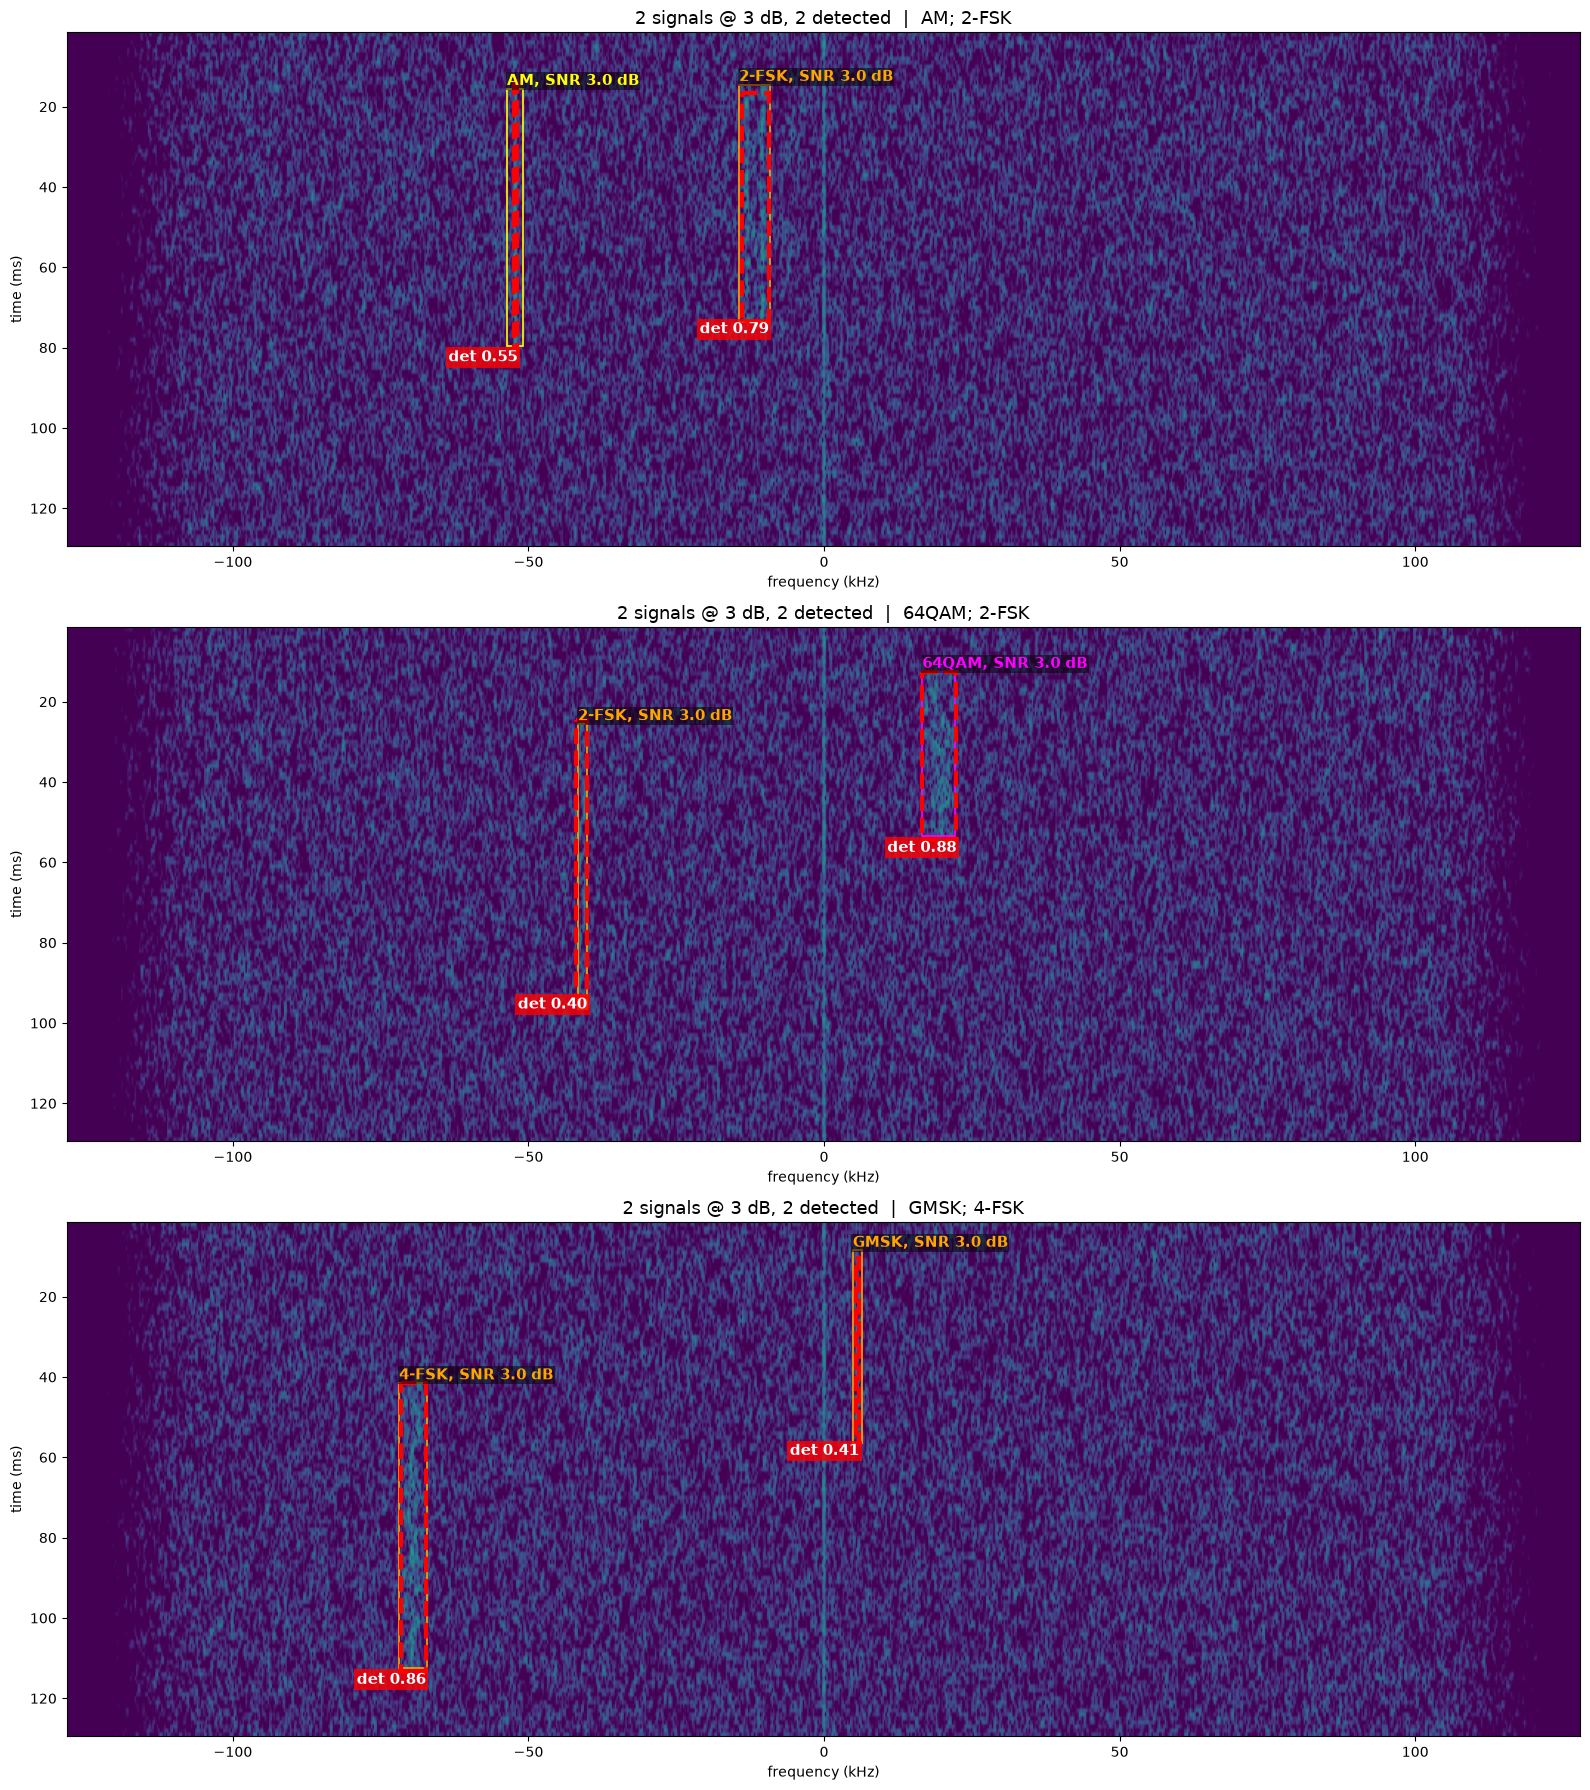

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(16, 18))
for ax, sc, pr in zip(axes, scs6[:3], prs6[:3]):
    draw(ax, sc, pr, f'2 signals @ {SNR6:.0f} dB, {len(pr)} detected  |  ' + "; ".join(f'{r["class_name"]}' for r in sc["signals"]))
plt.tight_layout()
plt.show()

## 7. One modulation hopping over 8 levels, each with a different dwell time

A single modulation (`HOP_CLS`) that **hops across 8 frequency levels** (20 kHz apart, visited in random order). Each hop stays on its level for a **different duration** (about 6 to 22 ms), separated by 1 ms gaps. Every hop is one ground-truth box, so the detector has to find 8 boxes of the same modulation with widths in time that all differ. The table lists each hop with its frequency, dwell time and IoU.

,modulation,center_kHz,start_ms,dwell_ms,snr_db,best_iou,detected
hop,,,,,,,
1,QPSK,50.1,2.0,19.6,8.0,0.77,True
2,QPSK,10.1,22.6,6.1,8.0,0.74,True
3,QPSK,-49.9,29.7,13.1,8.0,0.86,True
4,QPSK,70.1,43.8,8.7,8.0,0.89,True
5,QPSK,-69.9,53.5,10.3,8.0,0.83,True
6,QPSK,-9.9,64.8,17.3,8.0,0.94,True
7,QPSK,-29.9,83.1,22.1,8.0,0.83,True
8,QPSK,30.1,106.2,14.8,8.0,0.76,True


QPSK @ 8 dB: 8/8 hops found | detections: 8 | false positives: 0


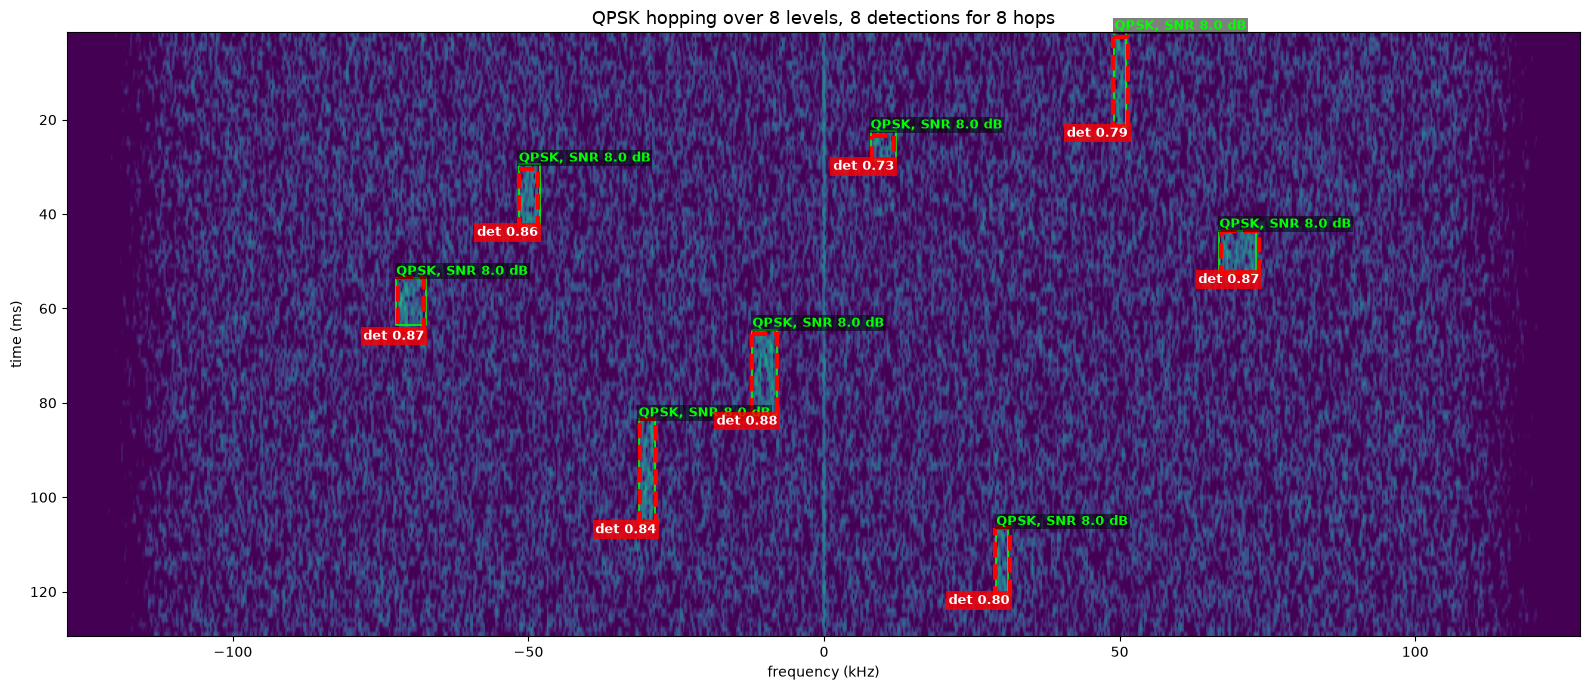

In [24]:
HOP_CLS, HOP_SNR, N_LEVELS = "QPSK", 8.0, 8                    # try any modulation from CLASSES; SNR in dB
rng7 = np.random.default_rng(None if SEED is None else SEED + 4)


def hop_scene(rng, name, cls=HOP_CLS, snr=HOP_SNR):
    levels = np.linspace(-70e3, 70e3, N_LEVELS)                # 8 frequency levels, 20 kHz apart
    order = rng.permutation(N_LEVELS)                          # visiting order
    dwell = rng.permutation(np.linspace(6.0, 22.0, N_LEVELS)) + rng.uniform(-0.4, 0.4, N_LEVELS)   # all different, ms
    t, items = 2.0, []
    for lv, d in zip(levels[order], dwell):
        items.append(dict(cls=cls, snr_db=snr, fc_hz=float(lv), t0_ms=t, t1_ms=t + float(d)))
        t += float(d) + 1.0                                    # 1 ms gap before the next hop
    assert t <= NS / MS, "hops do not fit in the scene"
    return make_demo_scene(items, rng.integers(0, 2**62), name)


sc7 = hop_scene(rng7, "hop_demo")
pr7 = det.detect_batch([sc7["db"]])[0]

gt7 = [tuple(r[c] for c in ("box_x0", "box_y0", "box_x1", "box_y1")) for r in sc7["signals"]]
iou7 = box_iou_matrix(gt7, [d["box"] for d in pr7])
rows7 = []
for j, r in enumerate(sc7["signals"]):
    best = float(iou7[j].max()) if iou7.shape[1] else 0.0
    rows7.append(dict(hop=j + 1, modulation=r["class_name"], center_kHz=round(r["center_hz"] / 1e3, 1),
                      start_ms=round(r["t_start_s"] * 1e3, 1), dwell_ms=round((r["t_end_s"] - r["t_start_s"]) * 1e3, 1),
                      snr_db=r["snr_db"], best_iou=round(best, 2), detected=best >= 0.5))
d7 = pd.DataFrame(rows7).sort_values("start_ms")
d7["hop"] = range(1, len(d7) + 1)
display(d7.set_index("hop"))
print(f"{HOP_CLS} @ {HOP_SNR:.0f} dB: {int(d7.detected.sum())}/{len(d7)} hops found | detections: {len(pr7)} | false positives: {len(pr7) - int(d7.detected.sum())}")

fig, ax = plt.subplots(1, 1, figsize=(16, 7))
draw(ax, sc7, pr7, f"{HOP_CLS} hopping over {N_LEVELS} levels, {len(pr7)} detections for {len(sc7['signals'])} hops", fs=9)
plt.tight_layout()
plt.show()